# Wnesny: first exploratory data analysis (M2)

This notebook loads the **synthetic** Wnesny dataset (generated by `python -m simulation.generate`, seed 42),
checks its quality and describes it. It is *descriptive only*: the confidence intervals and hypothesis tests
promised in the M1 proposal belong to M3.

**Important:** all data is simulated and the ratings come from an assumed model (`simulation/rating_model.py`),
so relationships such as "more shared interests, higher rating" are built in. They show that the generator works,
not that real riders behave this way.

Each *Finding* line below is printed by code, so the numbers always match the outputs.

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "raw"
if not (DATA / "trips.csv").exists():          # make the notebook runnable from a fresh clone
    from simulation.generate import generate, write_csv
    write_csv(generate(seed=42), DATA)

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.grid": True, "grid.alpha": .3})
areas = pd.read_csv(DATA / "areas.csv")
interests = pd.read_csv(DATA / "interests.csv")
users = pd.read_csv(DATA / "users.csv")
ui = pd.read_csv(DATA / "user_interests.csv")
trips = pd.read_csv(DATA / "trips.csv", parse_dates=["departure_at"])

## 1. Load and inspect

In [2]:
for name, df in [("areas", areas), ("interests", interests), ("users", users),
                 ("user_interests", ui), ("trips", trips)]:
    print(f"{name:15s} rows={len(df):5d}  columns={df.shape[1]:2d}  duplicate rows={df.duplicated().sum()}")
print()
print(trips.dtypes.to_string())

areas           rows=   50  columns= 6  duplicate rows=0
interests       rows=   32  columns= 3  duplicate rows=0
users           rows=  600  columns= 7  duplicate rows=0
user_interests  rows= 2967  columns= 2  duplicate rows=0
trips           rows= 3000  columns=12  duplicate rows=0

trip_id                         int64
driver_id                       int64
rider_id                        int64
origin_area_id                  int64
destination_area_id             int64
departure_at           datetime64[us]
distance_km                   float64
duration_min                  float64
detour_min                    float64
shared_interests                int64
is_peak                         int64
rating                          int64


In [3]:
missing = {n: int(d.isna().sum().sum()) for n, d in [("areas", areas), ("interests", interests),
           ("user_interests", ui), ("trips", trips)]}
print("Missing values per table:", missing)
print("users.avg_rating missing:", int(users.avg_rating.isna().sum()),
      "| users who never drove:", int((~users.user_id.isin(trips.driver_id)).sum()))
print("Finding: no missing values except avg_rating, which is empty exactly for users who never drove.")
assert users.avg_rating.isna().sum() == (~users.user_id.isin(trips.driver_id)).sum()

Missing values per table: {'areas': 0, 'interests': 0, 'user_interests': 0, 'trips': 0}
users.avg_rating missing: 333 | users who never drove: 333
Finding: no missing values except avg_rating, which is empty exactly for users who never drove.


In [4]:
print(trips[["distance_km", "duration_min", "detour_min", "shared_interests", "rating"]].describe().round(2).to_string())
bad = {"negative detour": int((trips.detour_min < 0).sum()), "non-positive distance": int((trips.distance_km <= 0).sum()),
       "rating outside 1-5": int((~trips.rating.between(1, 5)).sum()),
       "driver == rider": int((trips.driver_id == trips.rider_id).sum()),
       "origin == destination": int((trips.origin_area_id == trips.destination_area_id).sum())}
print("Oddities:", bad)
print("Finding: no negative values, no impossible ratings, no self-trips (the validator in simulation/validate.py enforces this).")

       distance_km  duration_min  detour_min  shared_interests   rating
count      3000.00       3000.00     3000.00           3000.00  3000.00
mean         29.13         66.80        7.07              0.80     3.15
std          19.08         51.26        4.99              1.15     0.91
min           3.04          3.70        0.00              0.00     1.00
25%          13.87         28.30        3.30              0.00     3.00
50%          25.99         54.30        6.00              0.00     3.00
75%          39.72         91.02        9.60              1.00     4.00
max         106.16        418.90       25.00              7.00     5.00
Oddities: {'negative detour': 0, 'non-positive distance': 0, 'rating outside 1-5': 0, 'driver == rider': 0, 'origin == destination': 0}
Finding: no negative values, no impossible ratings, no self-trips (the validator in simulation/validate.py enforces this).


## 2. Users and interests

Roles: {'rider': 333, 'driver': 212, 'both': 55}
Age groups: {'18-24': 240, '25-34': 199, '35-44': 98, '45+': 63}
Finding: 600 users; 333 riders, 212 drivers, 55 both; each user has 1 to 10 interests (mean 4.95, variance 4.77).


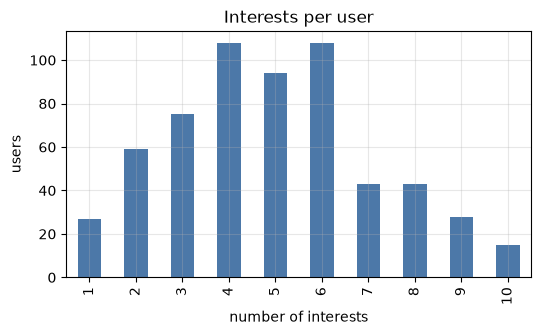

In [5]:
role = users.role.value_counts()
age = users.age_group.value_counts().reindex(["18-24", "25-34", "35-44", "45+"])
print("Roles:", role.to_dict()); print("Age groups:", age.to_dict())
per_user = ui.groupby("user_id").size()
print(f"Finding: {len(users)} users; {role['rider']} riders, {role['driver']} drivers, {role['both']} both; "
      f"each user has {per_user.min()} to {per_user.max()} interests (mean {per_user.mean():.2f}, variance {per_user.var():.2f}).")
fig, ax = plt.subplots(); per_user.value_counts().sort_index().plot.bar(ax=ax, color="#4c78a8")
ax.set(title="Interests per user", xlabel="number of interests", ylabel="users"); plt.show()

In [6]:
cat = ui.merge(interests, on="interest_id").groupby("category").size().sort_values(ascending=False)
top = ui.merge(interests, on="interest_id").groupby("name").size().sort_values(ascending=False)
print(cat.to_string())
print(f"Finding: the most common category is {cat.index[0]} ({cat.iloc[0]} user-interest pairs); "
      f"the most common interest is '{top.index[0]}' ({top.iloc[0]} users), the least common is '{top.index[-1]}' ({top.iloc[-1]} users).")

category
Technology          660
Sports              593
Business            436
Music               379
Arts & Culture      361
Lifestyle           271
Gaming & Hobbies    178
Social               89
Finding: the most common category is Technology (660 user-interest pairs); the most common interest is 'Software Development' (124 users), the least common is 'Photography' (60 users).


## 3. Trips: distance, duration, detour and time of day

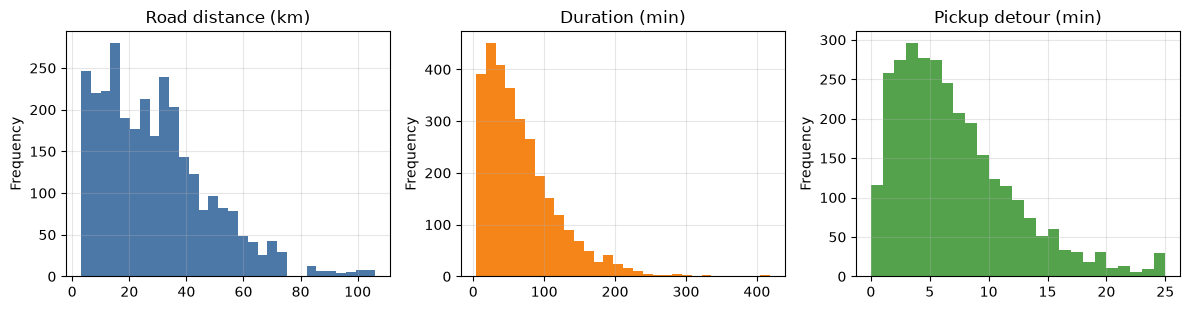

Finding: median distance 26.0 km, median duration 54.3 min, median detour 6.0 min; 76.9% of trips have a detour of 10 minutes or less.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
trips.distance_km.plot.hist(bins=30, ax=axes[0], color="#4c78a8", title="Road distance (km)")
trips.duration_min.plot.hist(bins=30, ax=axes[1], color="#f58518", title="Duration (min)")
trips.detour_min.plot.hist(bins=25, ax=axes[2], color="#54a24b", title="Pickup detour (min)")
plt.tight_layout(); plt.show()
print(f"Finding: median distance {trips.distance_km.median():.1f} km, median duration {trips.duration_min.median():.1f} min, "
      f"median detour {trips.detour_min.median():.1f} min; {100*(trips.detour_min <= 10).mean():.1f}% of trips have a detour of 10 minutes or less.")

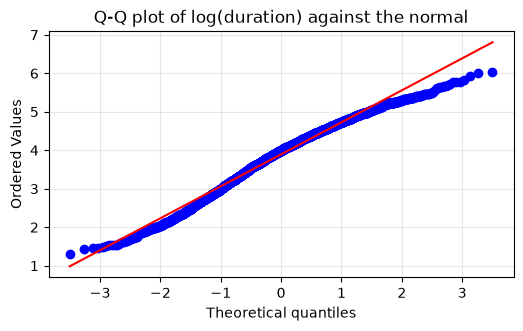

Finding: duration skewness is 1.55, but -0.43 after taking the logarithm, so a log-normal description looks reasonable (formal fit and test in M3).


In [8]:
# Is the duration log-normal? Check the skew of the raw and the log values, and a Q-Q plot of log(duration).
sk_raw, sk_log = stats.skew(trips.duration_min), stats.skew(np.log(trips.duration_min))
fig, ax = plt.subplots(); stats.probplot(np.log(trips.duration_min), dist="norm", plot=ax)
ax.set_title("Q-Q plot of log(duration) against the normal"); plt.show()
print(f"Finding: duration skewness is {sk_raw:.2f}, but {sk_log:.2f} after taking the logarithm, "
      "so a log-normal description looks reasonable (formal fit and test in M3).")

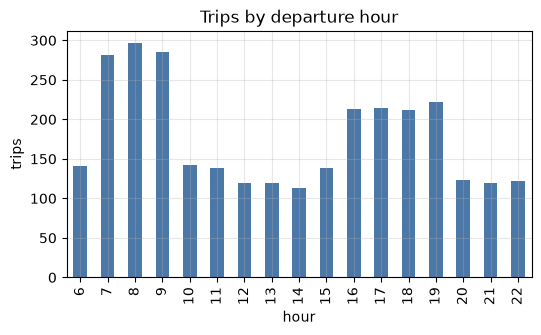

Finding: 57.5% of trips leave in peak hours (07-10 and 16-20); median speed is 22.0 km/h in peak and 38.3 km/h off-peak.


In [9]:
trips["hour"] = trips.departure_at.dt.hour
by_hour = trips.groupby("hour").size()
fig, ax = plt.subplots(); by_hour.plot.bar(ax=ax, color="#4c78a8"); ax.set(title="Trips by departure hour", ylabel="trips"); plt.show()
speed = trips.groupby("is_peak").apply(lambda g: (g.distance_km / g.duration_min * 60).median(), include_groups=False)
print(f"Finding: {100*trips.is_peak.mean():.1f}% of trips leave in peak hours (07-10 and 16-20); "
      f"median speed is {speed[1]:.1f} km/h in peak and {speed[0]:.1f} km/h off-peak.")

## 4. Shared interests

   observed  poisson_expected
0      1642            1352.5
1       785            1077.5
2       287             429.2
3       171             114.0
4        75              22.7
5        24               3.6
6        14               0.5
7         2               0.1


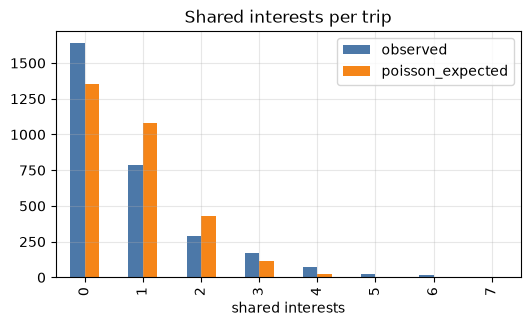

Finding: a trip has 0.80 shared interests on average (variance 1.32); 54.7% of trips share none. The variance is larger than the mean, so a plain Poisson is too narrow (to be tested in M3).


In [10]:
obs = trips.shared_interests.value_counts().sort_index()
lam = trips.shared_interests.mean()
exp = pd.Series({k: len(trips) * stats.poisson.pmf(k, lam) for k in obs.index})
cmp_ = pd.DataFrame({"observed": obs, "poisson_expected": exp.round(1)})
print(cmp_.to_string())
fig, ax = plt.subplots(); cmp_.plot.bar(ax=ax, color=["#4c78a8", "#f58518"]); ax.set(title="Shared interests per trip", xlabel="shared interests"); plt.show()
print(f"Finding: a trip has {lam:.2f} shared interests on average (variance {trips.shared_interests.var():.2f}); "
      f"{100*(trips.shared_interests == 0).mean():.1f}% of trips share none. "
      "The variance is larger than the mean, so a plain Poisson is too narrow (to be tested in M3).")

## 5. Ratings

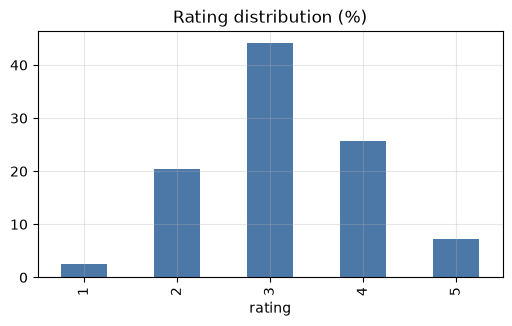

Finding: mean rating 3.15; 32.9% of trips are 'successful' (rating 4 or 5).


In [11]:
dist = trips.rating.value_counts(normalize=True).sort_index().mul(100).round(1)
fig, ax = plt.subplots(); dist.plot.bar(ax=ax, color="#4c78a8"); ax.set(title="Rating distribution (%)", xlabel="rating"); plt.show()
success = (trips.rating >= 4)
print(f"Finding: mean rating {trips.rating.mean():.2f}; {100*success.mean():.1f}% of trips are 'successful' (rating 4 or 5).")

In [12]:
peak = trips.groupby("is_peak").rating.agg(["count", "mean", lambda s: (s >= 4).mean()])
peak.columns = ["trips", "mean_rating", "success_rate"]; peak.index = ["off-peak", "peak"]
print(peak.round(3).to_string())
print(f"Finding: the success rate is {100*peak.loc['peak','success_rate']:.1f}% in peak hours and "
      f"{100*peak.loc['off-peak','success_rate']:.1f}% off-peak (statistical question 2 is tested in M3).")

          trips  mean_rating  success_rate
off-peak   1276        3.273         0.382
peak       1724        3.053         0.289
Finding: the success rate is 28.9% in peak hours and 38.2% off-peak (statistical question 2 is tested in M3).


               count  mean
shared_capped             
0               1642  2.81
1                785  3.21
2                287  3.73
3                171  4.16
4                115  4.57


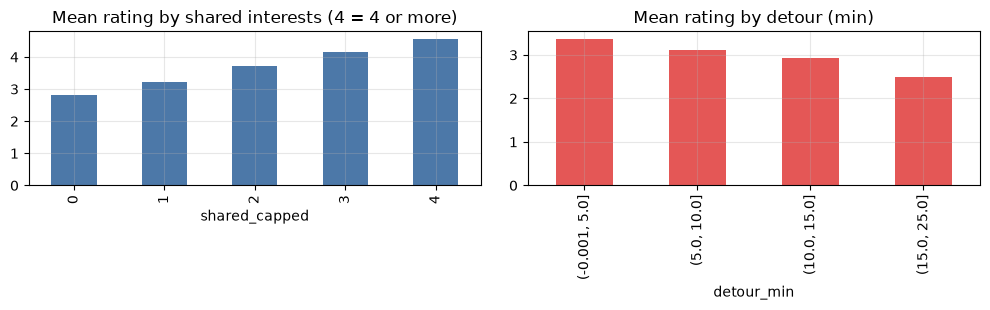

Finding: Spearman correlation with the rating is 0.48 for shared interests and -0.28 for detour. These signs are built into the simulation, so they only confirm that the generator behaves as designed.


In [13]:
by_shared = trips.assign(shared_capped=trips.shared_interests.clip(upper=4)).groupby("shared_capped").rating.agg(["count", "mean"]).round(2)
print(by_shared.to_string())
rho_s = stats.spearmanr(trips.shared_interests, trips.rating)
rho_d = stats.spearmanr(trips.detour_min, trips.rating)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
by_shared["mean"].plot.bar(ax=axes[0], color="#4c78a8", title="Mean rating by shared interests (4 = 4 or more)")
trips.groupby(pd.cut(trips.detour_min, [0, 5, 10, 15, 25], include_lowest=True), observed=True).rating.mean().plot.bar(
    ax=axes[1], color="#e45756", title="Mean rating by detour (min)")
plt.tight_layout(); plt.show()
print(f"Finding: Spearman correlation with the rating is {rho_s.statistic:.2f} for shared interests and {rho_d.statistic:.2f} for detour. "
      "These signs are built into the simulation, so they only confirm that the generator behaves as designed.")

## 6. Areas

In [14]:
a = areas.set_index("area_id").name
o = trips.origin_area_id.map(a).value_counts().head(5); d = trips.destination_area_id.map(a).value_counts().head(5)
print("Top origins:", o.to_dict()); print("Top destinations:", d.to_dict())
print(f"Finding: the busiest origin is {o.index[0]} ({o.iloc[0]} trips) and the busiest destination is {d.index[0]} ({d.iloc[0]} trips).")

Top origins: {'Nasr City': 143, 'New Cairo (5th Settlement)': 125, 'Cairo Airport': 122, '6th of October City': 111, 'Downtown': 104}
Top destinations: {'New Cairo (5th Settlement)': 126, 'Nasr City': 123, 'Sheikh Zayed': 110, 'Downtown': 110, 'AUC New Cairo': 107}
Finding: the busiest origin is Nasr City (143 trips) and the busiest destination is New Cairo (5th Settlement) (126 trips).


## 7. Limitations and next steps

* All data is simulated; area coordinates were typed in by hand and still need to be checked against OpenStreetMap.
* The rating model and its coefficients are assumptions, so results from this data say nothing about real passengers.
  The matcher must never use `simulation/rating_model.py` (a test checks this).
* The detour is drawn from a gamma distribution and is not computed from the rider's home area (documented simplification).
* **M3:** confidence intervals, Welch t-test with Mann-Whitney, chi-square for peak vs off-peak, regression, distribution fits, and the AI matching prototype.